## Test training


In [1]:
%load_ext autoreload
%autoreload 1

%aimport quantdata
%aimport quantdata.biz_calendar
%aimport quantdata.widb
%aimport quantdata.widb.client
%aimport quantdata.widb.day
%aimport quantdata.widb.sampler
%aimport quantdata.dysanos
%aimport quantdata.utils.backbone
%aimport quantdata.torch
%aimport quantdata.torch.bbtorch
%aimport quantdata.torch.ffw
%aimport quantdata.dysanos.simple
%aimport quantdata.dysanos.simple.sampler
%aimport quantdata.dysanos.simple.model
%aimport quantdata.dysanos.simple.trainer
%aimport quantdata.dysanos.simple.aec

from quantdata.dysanos.simple.aec import load_data
sampler = load_data(["SPX"])
print("/done")



00: Importing torch...done; this took 0.00358ms.
00: Generating samples for 1 tickers SPX with from 2015-01-01 to 2025-07-01... done; this took 0.26s.
00: Found the following number of samples per ticker: SPX: 2617.
00: Found date range 2015-01-02 to 2025-07-01 with 2617 total dates. First validation date for 25 steps per sample is 2023-05-01.
00: Using up to 1000 options per date.
01:   Ticker SPX: using 411 training samples (accross 2079 training dates), and 103 validation samples (accross 538 validation dates).
00: Created 411 training samples and 103 validation samples based on the date split at 2023-05-01. That implies 20% of all samples are validation samples.
00: Total time taken: 0.3s.
/done


## AEC

Cleaning up memory... done.
Model AEC train_sqrtVar_vol_linattn 1.1 [e1ef228d|acaee5f1ce9f88de] created.
00: Trainer for 'AEC train_sqrtVar_vol_linattn 1.1 [e1ef228d|acaee5f1ce9f88de]' on data acaee5f1ce9f88de
00: ====================================================================================================
01:   Model is ready. Current epoch to train is 0.
01:   Experiment path is /media/storage/quantdata/experiments/dysanos/simple/acaee5f1ce9f88de/v1/train_sqrtVar_vol_linattn 4cd34300/.
00: Launching 'AEC train_sqrtVar_vol_linattn 1.1 [e1ef228d|acaee5f1ce9f88de]' training for 1000 epochs over 411 training and 103 validation samples, using a mini bastch size of 128 for 10 batches per epoch, and a batch size of 128 for valuation. The model has 40497 parameters.
00: Training 'train_sqrtVar_vol_linattn' epoch 1/1000 error avg trn 859.3; val 175.4/190.6 [16s 2s 0.63s]. LR: 1.00e-03, GN 185.2, excess_weighted: 1.202e-12/3.593e-13, excess_weighted_avg: 0.0248/0.009502, excess_spread: 

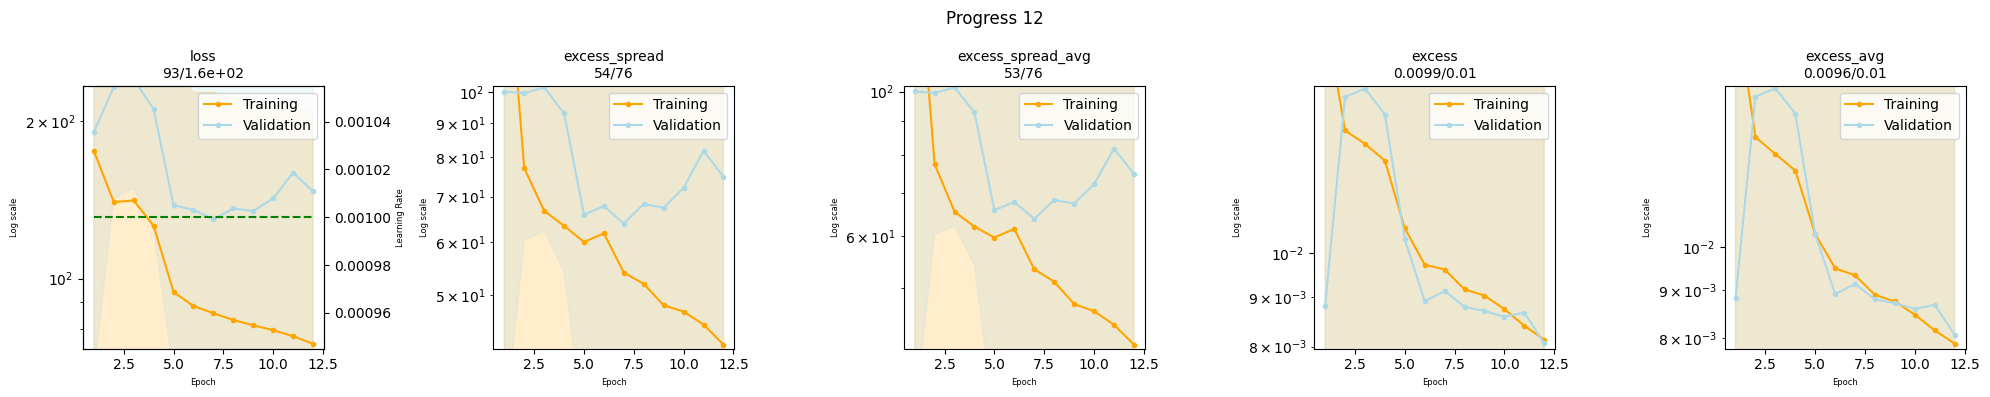

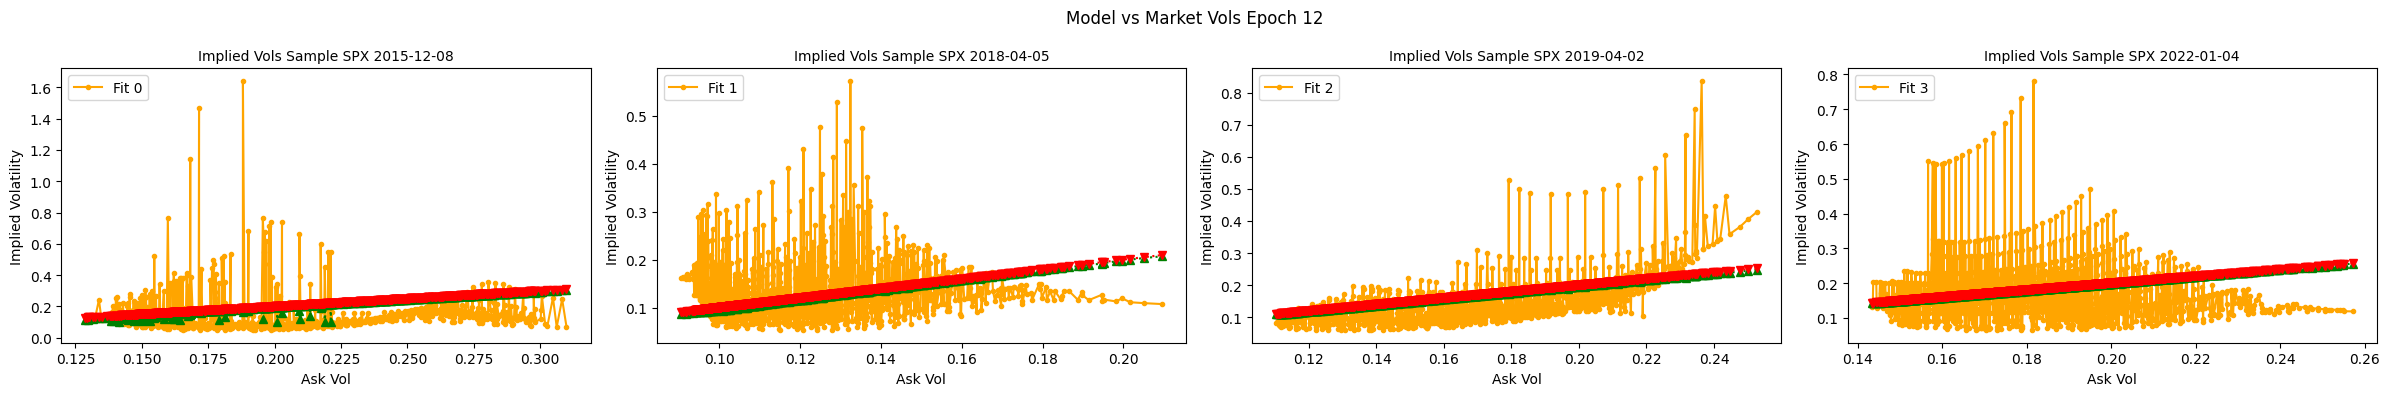

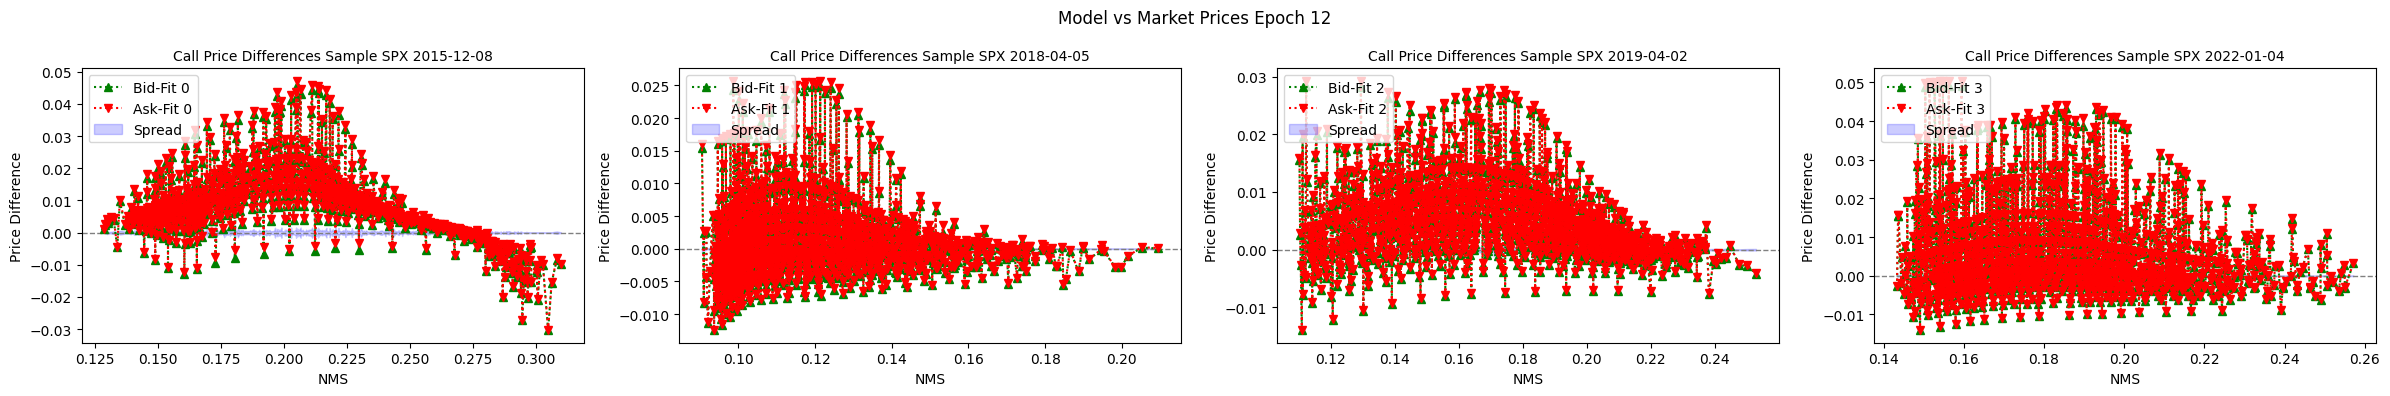

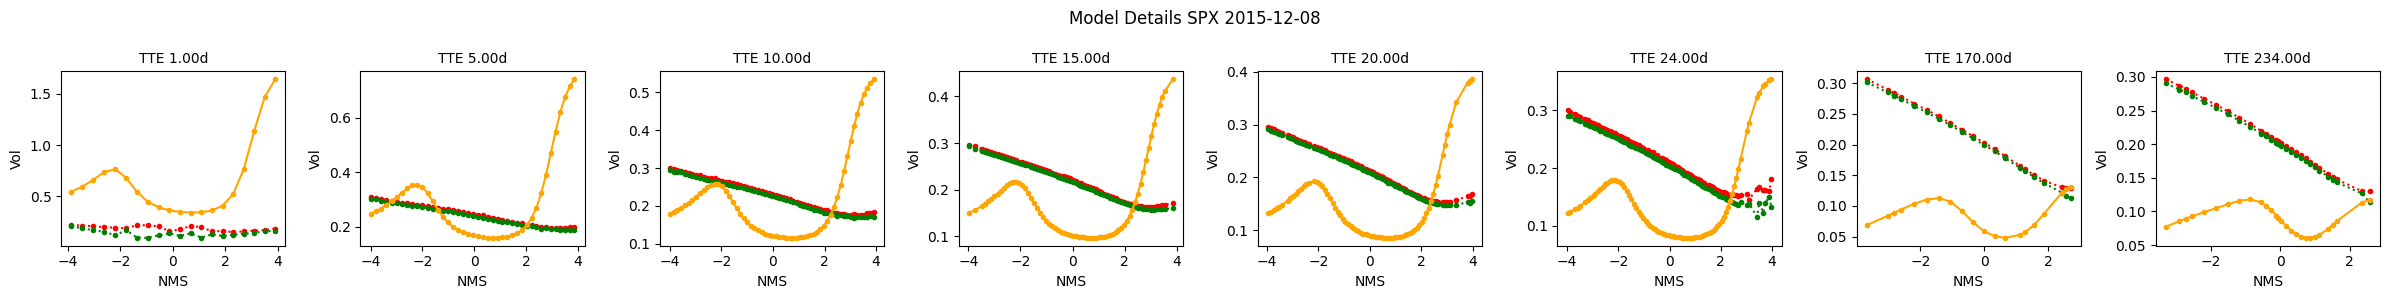

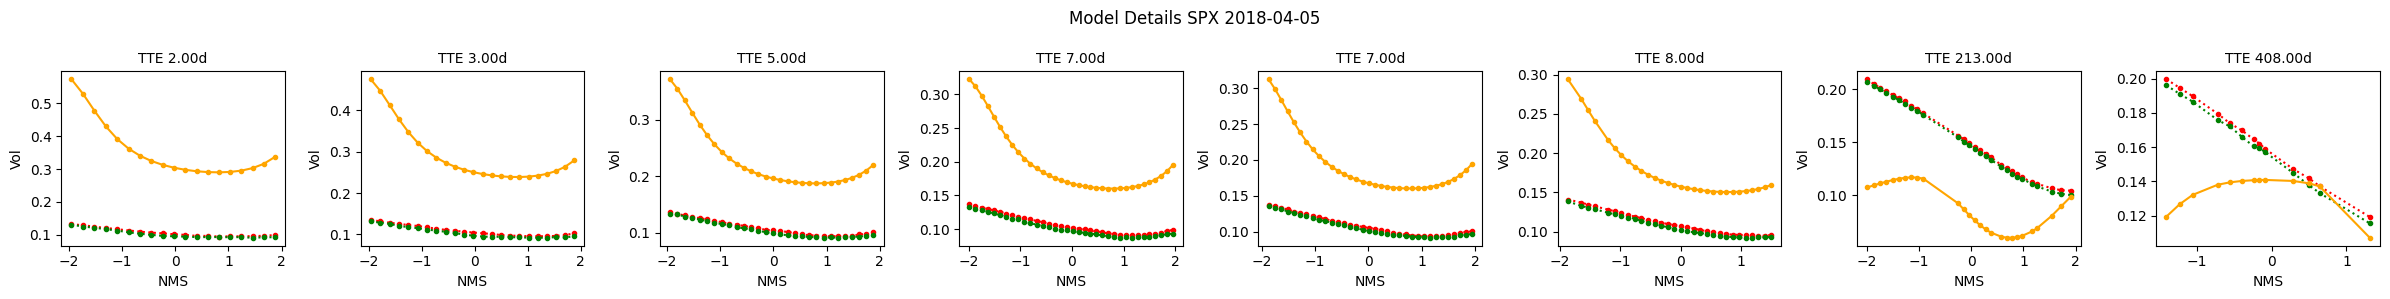

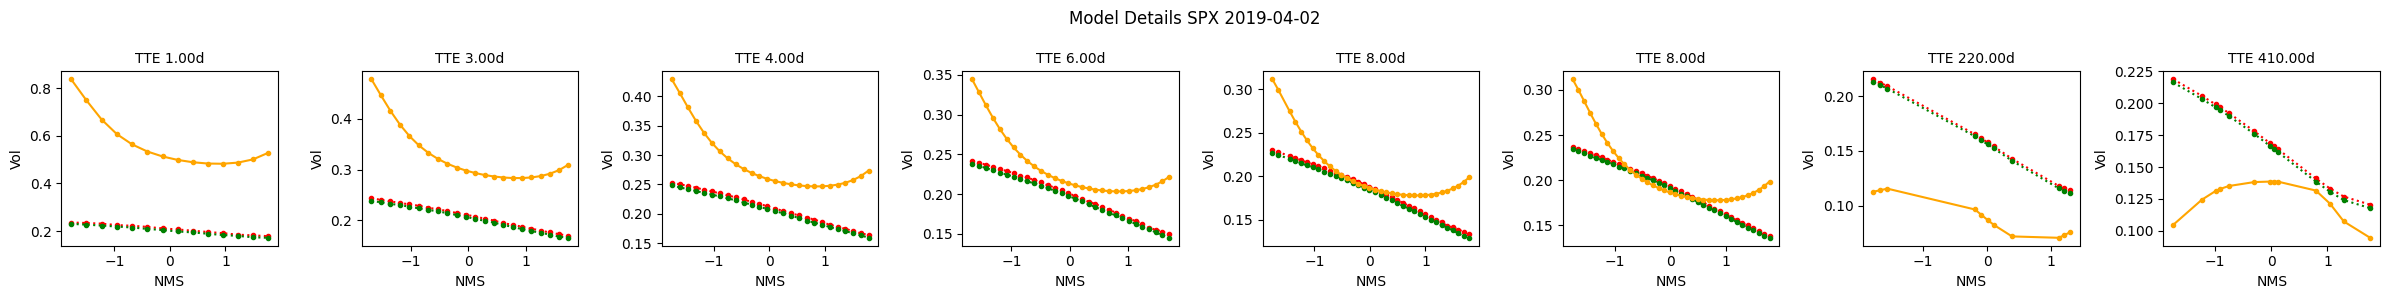

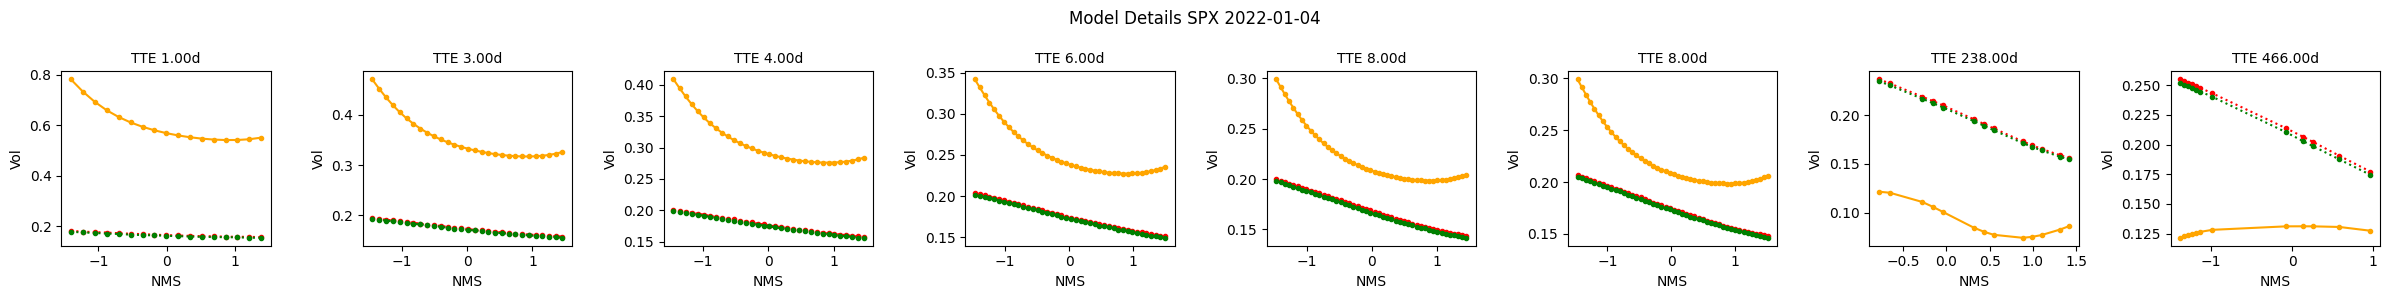

00: Training 'train_sqrtVar_vol_linattn' epoch 2/1000 error avg trn 137.3; val 140/232.3 [16s 2s 0.63s]. LR: 1.00e-03, GN 21.41, excess_weighted: 5.213e-13/3.573e-13, excess_weighted_avg: 0.01162/0.01053, excess_spread: 77.12/99.52, excess_spread_avg: 77.37/99.52, excess: 0.01338/0.01448, excess_avg: 0.01311/0.01448. ETA: 11:24:56.
00: Training 'train_sqrtVar_vol_linattn' epoch 3/1000 error avg trn 141.5; val 141.1/240.5 [16s 2s 0.63s]. LR: 1.00e-03, GN 22.53, excess_weighted: 4.531e-13/3.644e-13, excess_weighted_avg: 0.009973/0.01073, excess_spread: 66.7/101.5, excess_spread_avg: 65.45/101.5, excess: 0.01296/0.01478, excess_avg: 0.01257/0.01478. ETA: 17:16:46.
00: Training 'train_sqrtVar_vol_linattn' epoch 4/1000 error avg trn 136.7; val 126.1/210.8 [16s 2s 0.63s]. LR: 1.00e-03, GN 31.83, excess_weighted: 4.303e-13/3.335e-13, excess_weighted_avg: 0.009494/0.009886, excess_spread: 63.35/92.9, excess_spread_avg: 62.09/92.9, excess: 0.01245/0.01389, excess_avg: 0.01207/0.01389. ETA: 23:0

In [ ]:
from quantdata.dysanos.simple.model import *
from quantdata.dysanos.simple.aec import *

aec_config = AEC.Config(
    # core pararmeters
    encode_what = "sqrtVar",
    fit_what    = "vol",
    num_state   = 64,
    fit_average = True,

    # rarely touch these
    weight_by_spread = True,

    encoder = AttentionEncoderFactory(
        num_head = 64,
        num_QK = 8,
        V_config = FeedForward.Config(
            num_depth = 0, # linear
            num_width = 64, # head
            activation = 'Softplus',
        ),
        QK_config = FeedForward.Config(
            num_depth = 0,  # linear
            num_width = 16, # twice num_QK
            activation = 'ReLU', # idea is to be sparse...?
        ),
        head_config = FeedForward.Config(
            num_depth = 2,
            num_width = 64, # head
            activation = 'ReLU', # idea is to be sparse...?
        )
    ),
    decoder = GatingDecoderFactory(
        num_head = 16,
        num_QK = 4,        
        V_config = FeedForward.Config(
            num_depth = 2,
            num_width = 32, # twice head
            activation = 'Softplus',    
        ),
        QK_config = FeedForward.Config(
            num_depth = 0, # linear
            num_width = 4, # equal QK
            activation = 'ReLU', # idea is to be sparse...?
        ),
        head_config = FeedForward.Config(
            num_depth = 2,
            num_width = 32, # twice head
            activation = 'Softplus',
        )
    ),
)

run( ipynbname.name(), version="1.1", aec_config=aec_config, sampler=sampler, epochs = 1000, batch_per_epoch = 10, debug=False, val_batch_size=128 )
